# Baseline Classification Models

This notebook builds baseline classifiers using the engineered features from 01_eda.ipynb.
Target: Predict stellar class (GALAXY, QSO, STAR)

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# --- Load and Engineer Data ---
train_path = "/workspaces/KagglePredictingStellarClass/data/train.csv"
df = pd.read_csv(train_path)

# Feature engineering (same as 01_eda.ipynb Cell 6)
df_eng = df.drop(columns=["id"]).copy()

# Color indices
df_eng["u_g"] = df_eng["u"] - df_eng["g"]
df_eng["g_r"] = df_eng["g"] - df_eng["r"]
df_eng["r_i"] = df_eng["r"] - df_eng["i"]
df_eng["i_z"] = df_eng["i"] - df_eng["z"]

# Drop raw bands
df_eng = df_eng.drop(columns=["u", "g", "r", "i", "z"])

# Label-encode categoricals
for col in ["spectral_type", "galaxy_population"]:
    df_eng[col] = LabelEncoder().fit_transform(df_eng[col])

print(f"Engineered dataset shape: {df_eng.shape}")
print(f"\nFeatures: {[c for c in df_eng.columns if c != 'class']}")

Engineered dataset shape: (577347, 10)

Features: ['alpha', 'delta', 'redshift', 'spectral_type', 'galaxy_population', 'u_g', 'g_r', 'r_i', 'i_z']


In [3]:
# --- Prepare train/test split ---
X = df_eng.drop(columns=["class"])
y = df_eng["class"]

# Encode target
le_target = LabelEncoder()
y_encoded = le_target.fit_transform(y)
class_names = le_target.classes_

print(f"Target classes: {class_names}")
print(f"Feature matrix shape: {X.shape}")
print(f"Target shape: {y_encoded.shape}")

# 80-20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"\nTrain set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

Target classes: ['GALAXY' 'QSO' 'STAR']
Feature matrix shape: (577347, 9)
Target shape: (577347,)

Train set size: 461877
Test set size: 115470


In [4]:
# --- Baseline: Random Forest ---
print("Training Random Forest Classifier...")
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1,
    verbose=0
)

rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print("Random Forest training complete!")

Training Random Forest Classifier...
Random Forest training complete!


In [5]:
# --- Evaluation Metrics ---
accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average="macro")
recall_macro = recall_score(y_test, y_pred, average="macro")
f1_macro = f1_score(y_test, y_pred, average="macro")

print("=== Baseline Random Forest Results ===")
print(f"Accuracy:        {accuracy:.4f}")
print(f"Precision (macro): {precision_macro:.4f}")
print(f"Recall (macro):    {recall_macro:.4f}")
print(f"F1-Score (macro):  {f1_macro:.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=class_names))

=== Baseline Random Forest Results ===
Accuracy:        0.9505
Precision (macro): 0.9346
Recall (macro):    0.9323
F1-Score (macro):  0.9334

=== Classification Report ===
              precision    recall  f1-score   support

      GALAXY       0.96      0.97      0.96     75496
         QSO       0.95      0.95      0.95     23429
        STAR       0.89      0.88      0.88     16545

    accuracy                           0.95    115470
   macro avg       0.93      0.93      0.93    115470
weighted avg       0.95      0.95      0.95    115470



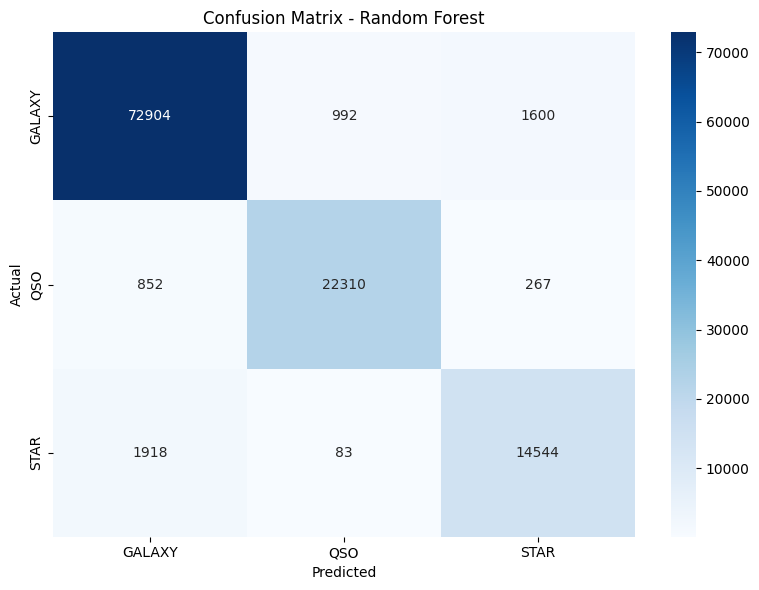

In [6]:
# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()

Feature Importance (Top 10):


,feature,importance
2,redshift,0.423905
6,g_r,0.192573
7,r_i,0.125026
5,u_g,0.063821
4,galaxy_population,0.063426
3,spectral_type,0.041932
8,i_z,0.035975
0,alpha,0.030041
1,delta,0.023301


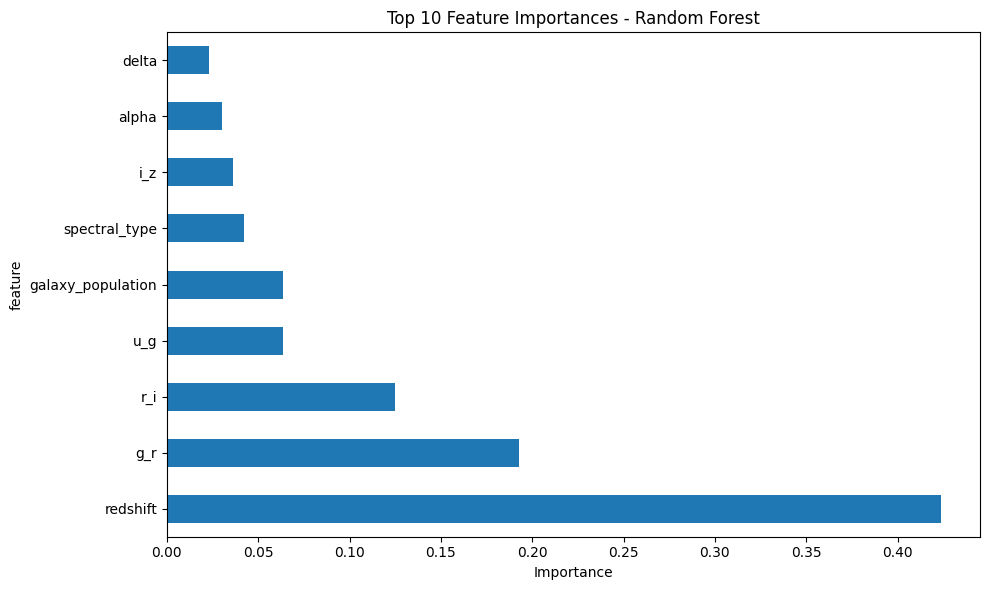

In [7]:
# --- Feature Importance ---
feature_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

print("Feature Importance (Top 10):")
display(feature_importance.head(10))

fig, ax = plt.subplots(figsize=(10, 6))
feature_importance.head(10).plot(x="feature", y="importance", kind="barh", ax=ax, legend=False)
ax.set_xlabel("Importance")
ax.set_title("Top 10 Feature Importances - Random Forest")
plt.tight_layout()
plt.show()

In [8]:
# --- Cross-Validation ---
print("Running 5-fold cross-validation...")
cv_scores = cross_val_score(rf, X_train, y_train, cv=5, scoring="accuracy", n_jobs=-1)

print(f"\nCross-validation fold scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

Running 5-fold cross-validation...

Cross-validation fold scores: [0.95098294 0.94925089 0.95117727 0.95030041 0.95061434]
Mean CV Accuracy: 0.9505 (+/- 0.0007)
